# Dự đoán giá ô tô: 2 mô hình × 2 cách cài đặt

**Bài toán:** hồi quy, dự đoán giá bán (triệu đồng) từ các đặc trưng của xe. Dữ liệu: `clean_data_oto.csv` (đã làm sạch ở `preprocess_data.ipynb`).

**Hai mô hình được chọn và lý do**

| Mô hình | Vai trò | Vì sao chọn |
|---|---|---|
| **Ridge Regression** (hồi quy tuyến tính + L2) | mô hình tuyến tính, đơn giản, giải thích được | Làm mốc so sánh; có nghiệm đóng nên cài đặt từ đầu gọn và có thể kiểm chứng; hệ số cho biết mỗi đặc trưng làm giá tăng giảm bao nhiêu % (vì dự đoán log giá). L2 cần thiết vì sau one-hot có ~170 cột tương quan với nhau (hãng, dòng xe, kiểu dáng...) |
| **Random Forest** (rừng cây hồi quy) | mô hình phi tuyến, mạnh trên dữ liệu bảng | Giá xe phụ thuộc phi tuyến và tương tác (xe Mercedes khấu hao khác Toyota; km quan trọng khác nhau theo đời xe) mà mô hình tuyến tính không bắt được; ít cần chuẩn hóa; có OOB để ước lượng sai số và độ quan trọng đặc trưng |

Ngoài ra có **Decision Tree** (một cây hồi quy) làm mốc trung gian: đề bài nêu tên mô hình này, và đặt nó cạnh Random Forest cho thấy việc lấy trung bình nhiều cây giảm sai số được bao nhiêu so với một cây.

**Mỗi mô hình được viết 2 hướng:** (A) dùng thư viện `scikit-learn`; (B) tự cài đặt thuật toán bằng `numpy` (không gọi lại mô hình của thư viện), rồi so sánh để kiểm chứng bản tự cài đặt cho kết quả tương đương.

**Quy trình chung:** chia train/test có phân tầng theo phân khúc giá → mã hóa/chuẩn hóa (fit trên train) → tinh chỉnh tham số **chỉ bằng dữ liệu train** (cross-validation hoặc OOB) → đánh giá **một lần** trên test → so sánh. Các lựa chọn về dữ liệu (log giá, kỹ thuật cân bằng) cũng chỉ được quyết định bằng CV trên train (mục 7).

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True})
BLUE, ORANGE, GREEN, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
RANDOM_STATE = 42
rng_global = np.random.RandomState(RANDOM_STATE)

## 1. Dữ liệu, chia train/test, mã hóa

In [2]:
df = pd.read_csv("clean_data_oto.csv")
print(df.shape)
df.head(3)

(13946, 16)


,carbrand,carbrand_grp,carmodel,carmodel_grp,carorigin,condition_ad,gearbox,fuel,cartype,carseats,mfdate,age,mileage_km,km_per_year,price_tr,price_log
0,Toyota,Toyota,Vios,Toyota Vios,Việt Nam,Đã sử dụng,Tự động,Xăng,Sedan,5,2018,8,109366.0,13670.75,309.0,5.733341
1,Peugeot,Peugeot,3008,Peugeot 3008,Việt Nam,Đã sử dụng,Tự động,Xăng,SUV / Cross over,5,2022,4,30000.0,7500.00,697.0,6.546785
2,Toyota,Toyota,Fortuner,Toyota Fortuner,Nước khác,Đã sử dụng,Tự động,Xăng,SUV / Cross over,7,2018,8,90000.0,11250.00,650.0,6.476972


### 1.1 Đặc trưng và biến mục tiêu
- **Biến mục tiêu:** `price_log` = ln(giá). Lý do ở `preprocess_data.ipynb` (mục 7.1); mục 7 của notebook này kiểm chứng bằng CV trên train rằng huấn luyện trên log giá cho MAPE thấp hơn trên giá gốc. Dự đoán xong dùng `exp()` để đổi về triệu đồng và **mọi metric đều tính trên thang giá thật**. Lưu ý: `exp()` của dự đoán trên thang log ước lượng **trung vị** của giá chứ không phải trung bình (hơi thấp hơn trung bình). Điều này phù hợp với MAPE, nên không hiệu chỉnh.
- **Phân loại (one-hot):** hãng (gộp nhãn hiếm), dòng xe (gộp), xuất xứ, tình trạng, hộp số, nhiên liệu, kiểu dáng.
- **Số:** tuổi xe, số km, số chỗ, km/năm. Với mô hình tuyến tính, thêm `age²` và dùng `log1p` cho các cột lệch phải (km, km/năm) để quan hệ gần tuyến tính hơn: xe mất giá nhanh trong những năm đầu rồi chậm lại, và 10.000 km đầu "đắt" hơn 10.000 km sau. Các cột thêm này vô hại với Random Forest nên dùng chung một ma trận đặc trưng cho cả hai mô hình.
- **Không** đưa `price_tr`, `price_log` (đáp án) và `mfdate` (trùng `age`) vào đặc trưng.

In [3]:
CAT = ["carbrand_grp", "carmodel_grp", "carorigin", "condition_ad", "gearbox", "fuel", "cartype"]

d = df.copy()
d["age_sq"] = d["age"] ** 2
d["log_km"] = np.log1p(d["mileage_km"])
d["log_km_per_year"] = np.log1p(d["km_per_year"])
NUM = ["age", "age_sq", "log_km", "carseats", "log_km_per_year"]

SEG_BINS = [0, 200, 500, 1000, 2000, np.inf]
SEG_LABELS = ["< 200 triệu", "200-500", "500-1.000", "1-2 tỷ", "> 2 tỷ"]
d["segment"] = pd.cut(d["price_tr"], bins=SEG_BINS, labels=SEG_LABELS, right=False)

# chia 80/20, phân tầng theo phân khúc giá để tập test có đủ xe sang
idx_tr, idx_te = train_test_split(d.index, test_size=0.2, stratify=d["segment"], random_state=RANDOM_STATE)
tr, te = d.loc[idx_tr], d.loc[idx_te]

prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ("num", StandardScaler(), NUM),
])
X_tr = prep.fit_transform(tr[CAT + NUM])          # fit chỉ trên train
X_te = prep.transform(te[CAT + NUM])
feature_names = list(prep.get_feature_names_out())

y_tr, y_te = tr["price_log"].values, te["price_log"].values        # thang log: để huấn luyện
p_tr, p_te = tr["price_tr"].values, te["price_tr"].values          # thang triệu đồng: để đánh giá
seg_tr, seg_te = tr["segment"].astype(str).values, te["segment"].astype(str).values

print(f"Train {X_tr.shape} | Test {X_te.shape} | số đặc trưng: {len(feature_names)}")

Train (11156, 171) | Test (2790, 171) | số đặc trưng: 171


## 2. Thước đo đánh giá

Chọn nhiều thước đo vì mỗi cái trả lời một câu hỏi khác nhau; tất cả tính trên **thang giá thật (triệu đồng)**:

| Metric | Ý nghĩa | Vì sao dùng |
|---|---|---|
| **MAE** | sai số tuyệt đối trung bình (triệu) | Dễ hiểu: "dự đoán lệch trung bình bao nhiêu tiền" |
| **RMSE** | căn sai số bình phương trung bình (triệu) | Phạt nặng lỗi lớn (đoán sai xe sang) |
| **MAPE** | sai số phần trăm trung bình | **Thước đo chính**: lệch 100 triệu là nhỏ với xe 3 tỷ nhưng lớn với xe 150 triệu |
| **MedAPE** | trung vị sai số phần trăm | Bền với vài mẫu sai quá lớn, phản ánh sai số "điển hình" |
| **R² (giá)** | tỉ lệ phương sai giá được giải thích | Chuẩn học thuật; nhưng bị chi phối bởi xe đắt |
| **R² (log giá)** | R² trên thang log | Đo chất lượng mô hình trên đúng thang đã huấn luyện |
| **±10% / ±20%** | tỉ lệ dự đoán lệch dưới 10% / 20% | Diễn giải cho người dùng: "bao nhiêu % tin đăng được định giá khá sát" |

Ngoài ra báo cáo **MAPE theo từng phân khúc giá** vì một con số trung bình che giấu việc mô hình kém ở xe sang.

In [4]:
def regression_metrics(p_true, p_pred):
    p_pred = np.clip(p_pred, 1, None)
    err = p_pred - p_true
    ape = np.abs(err) / p_true
    ss_res = np.sum((p_true - p_pred) ** 2)
    ss_tot = np.sum((p_true - p_true.mean()) ** 2)
    lt, lp = np.log(p_true), np.log(p_pred)
    return {
        "MAE (triệu)": np.mean(np.abs(err)),
        "RMSE (triệu)": np.sqrt(np.mean(err ** 2)),
        "MAPE": ape.mean(),
        "MedAPE": np.median(ape),
        "R2 (giá)": 1 - ss_res / ss_tot,
        "R2 (log)": 1 - np.sum((lt - lp) ** 2) / np.sum((lt - lt.mean()) ** 2),
        "±10%": np.mean(ape <= 0.10),
        "±20%": np.mean(ape <= 0.20),
    }

def segment_mape(p_true, p_pred, seg):
    ape = np.abs(np.clip(p_pred, 1, None) - p_true) / p_true
    return {f"MAPE {s}": ape[seg == s].mean() for s in SEG_LABELS}

results, preds = {}, {}
def record(name, log_pred, fit_seconds):
    """log_pred: dự đoán trên thang log. Lưu metric trên thang giá thật."""
    p_pred = np.exp(log_pred)
    preds[name] = p_pred
    results[name] = {**regression_metrics(p_te, p_pred), **segment_mape(p_te, p_pred, seg_te), "Thời gian fit (s)": fit_seconds}
    return pd.Series(results[name]).round(3)

# Mốc so sánh: luôn đoán trung vị giá của tập train
t0 = time.time()
dummy = DummyRegressor(strategy="median").fit(X_tr, y_tr)
record("Baseline (trung vị)", dummy.predict(X_te), time.time() - t0)

MAE (triệu)          337.689
RMSE (triệu)         724.379
MAPE                   0.849
MedAPE                 0.404
R2 (giá)              -0.047
R2 (log)              -0.003
±10%                   0.137
±20%                   0.255
MAPE < 200 triệu       3.598
MAPE 200-500           0.384
MAPE 500-1.000         0.307
MAPE 1-2 tỷ            0.639
MAPE > 2 tỷ            0.854
Thời gian fit (s)      0.001
dtype: float64

## 3. Mô hình 1: Ridge Regression

Mô hình: $\hat y = w_0 + \sum_j w_j x_j$, với hàm mất mát

$$J(w) = \frac{1}{2n}\sum_i (y_i - \hat y_i)^2 + \frac{\alpha}{2}\lVert w\rVert_2^2 \quad (w_0 \text{ không bị phạt})$$

`alpha` là **siêu tham số cần tinh chỉnh**: quá nhỏ → overfit vì các cột one-hot tương quan; quá lớn → các hệ số bị co về 0, underfit.

### 3A. Dùng thư viện (`sklearn.linear_model.Ridge`)
Tinh chỉnh `alpha` bằng **Grid Search + 5-fold cross-validation**, thước đo là RMSE trên log giá.

alpha tốt nhất (sklearn): 0.3162 | CV RMSE (log) = 0.3259


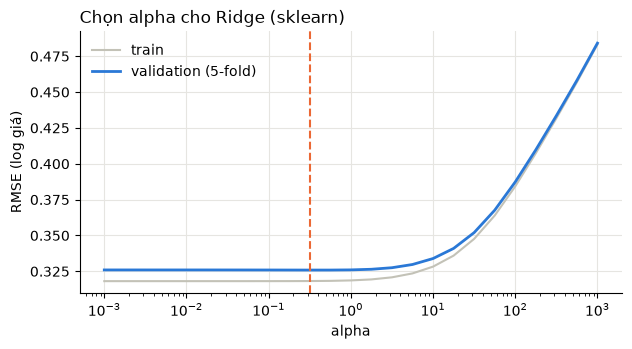

In [5]:
alphas = np.logspace(-3, 3, 25)
t0 = time.time()
gs_ridge = GridSearchCV(Ridge(), {"alpha": alphas}, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                        scoring="neg_root_mean_squared_error", n_jobs=-1, return_train_score=True)
gs_ridge.fit(X_tr, y_tr)
t_ridge_lib = time.time() - t0

best_alpha_lib = gs_ridge.best_params_["alpha"]
print(f"alpha tốt nhất (sklearn): {best_alpha_lib:.4g} | CV RMSE (log) = {-gs_ridge.best_score_:.4f}")

cvr = pd.DataFrame(gs_ridge.cv_results_)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(cvr["param_alpha"].astype(float), -cvr["mean_train_score"], color=GRAY, label="train")
ax.plot(cvr["param_alpha"].astype(float), -cvr["mean_test_score"], color=BLUE, lw=2, label="validation (5-fold)")
ax.axvline(best_alpha_lib, color=ORANGE, ls="--")
ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.set_ylabel("RMSE (log giá)")
ax.set_title("Chọn alpha cho Ridge (sklearn)", loc="left")
ax.legend(frameon=False)
plt.show()

In [6]:
t0 = time.time()
ridge_lib = Ridge(alpha=best_alpha_lib).fit(X_tr, y_tr)
record("Ridge - thư viện", ridge_lib.predict(X_te), time.time() - t0)   # chỉ tính thời gian fit cuối, không tính tìm alpha

MAE (triệu)          147.033
RMSE (triệu)         469.650
MAPE                   0.220
MedAPE                 0.121
R2 (giá)               0.560
R2 (log)               0.829
±10%                   0.432
±20%                   0.691
MAPE < 200 triệu       0.476
MAPE 200-500           0.179
MAPE 500-1.000         0.146
MAPE 1-2 tỷ            0.187
MAPE > 2 tỷ            0.469
Thời gian fit (s)      0.024
dtype: float64

### 3B. Tự cài đặt bằng NumPy
Hai cách tìm `w`, đều tự viết:

1. **Nghiệm đóng (normal equation):** đạo hàm $J$ theo $w$ bằng 0 cho $w = (X^TX + n\alpha I')^{-1}X^Ty$, với $I'$ là ma trận đơn vị nhưng phần tử của bias bằng 0 (không phạt bias). Chính xác, giải một lần.
2. **Gradient Descent (có momentum Nesterov):** lặp $w \leftarrow v - \eta\,\nabla J(v)$, $v \leftarrow w_{new} + \frac{t-1}{t+2}(w_{new} - w)$, với $\nabla J = \frac1n X^T(Xw-y) + \alpha w'$. Bước học $\eta = 1/L$ với $L$ là trị riêng lớn nhất của Hessian (đảm bảo hội tụ). Dùng để minh họa quá trình tối ưu và **kiểm chứng** với nghiệm đóng.

`alpha` được chọn bằng **K-fold cross-validation tự viết**.

alpha tốt nhất (tự cài đặt): 0.5623 (sklearn chọn 0.3162) | CV RMSE (log) = 0.3259


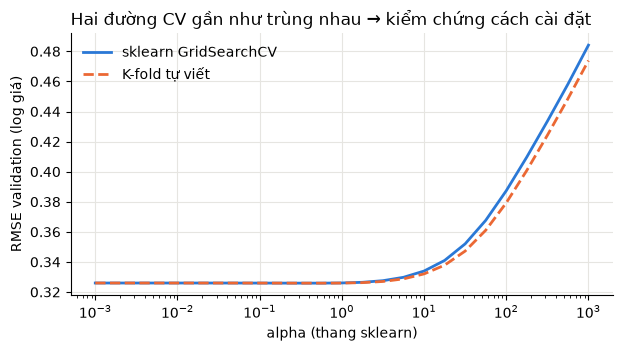

In [7]:
class RidgeScratch:
    """Ridge regression: nghiệm đóng hoặc gradient descent (bias không bị phạt)."""

    def __init__(self, alpha=1.0, solver="closed", lr=None, n_iter=3000, tol=1e-9):
        self.alpha, self.solver, self.lr, self.n_iter, self.tol = alpha, solver, lr, n_iter, tol

    @staticmethod
    def _add_bias(X):
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def fit(self, X, y):
        A = self._add_bias(X)
        n, p = A.shape
        reg = np.eye(p)
        reg[0, 0] = 0.0                                   # không phạt bias
        if self.solver == "closed":
            # (AᵀA/n + αI') w = Aᵀy/n  (giải hệ, không nghịch đảo trực tiếp để ổn định số)
            self.w_ = np.linalg.solve(A.T @ A / n + self.alpha * reg, A.T @ y / n)
        else:
            H = A.T @ A / n + self.alpha * reg            # Hessian của J
            lr = self.lr or 1.0 / np.linalg.eigvalsh(H).max()
            w = np.zeros(p)
            v = w.copy()                                  # điểm "nhìn trước" của Nesterov
            self.loss_ = []
            for t in range(1, self.n_iter + 1):
                resid = A @ v - y
                grad = A.T @ resid / n + self.alpha * (reg @ v)
                w_new = v - lr * grad
                v = w_new + (t - 1) / (t + 2) * (w_new - w)   # momentum Nesterov
                w = w_new
                self.loss_.append(0.5 * np.mean((A @ w - y) ** 2) + 0.5 * self.alpha * np.sum(w[1:] ** 2))
                if np.linalg.norm(grad) < self.tol:
                    break
            self.w_ = w
        self.intercept_, self.coef_ = self.w_[0], self.w_[1:]
        return self

    def predict(self, X):
        return self._add_bias(X) @ self.w_


def kfold_indices(n, k, seed):
    """Tự viết K-fold: xáo trộn rồi cắt thành k phần."""
    idx = np.random.RandomState(seed).permutation(n)
    folds = np.array_split(idx, k)
    for i in range(k):
        yield np.concatenate(folds[:i] + folds[i + 1:]), folds[i]


def cv_rmse_ridge(X, y, alpha, k=5, seed=RANDOM_STATE):
    errs = []
    for tr_i, va_i in kfold_indices(len(y), k, seed):
        m = RidgeScratch(alpha).fit(X[tr_i], y[tr_i])
        errs.append(np.sqrt(np.mean((m.predict(X[va_i]) - y[va_i]) ** 2)))
    return np.mean(errs)

# Lưu ý: sklearn Ridge tối thiểu hóa ||y-Xw||² + alpha||w||² (không chia n), còn bản tự viết chia n,
# nên alpha_scratch = alpha_sklearn / n để cùng một mô hình. Dùng lưới alpha theo thang sklearn rồi quy đổi.
n_tr = len(y_tr)
t0 = time.time()
cv_scores = np.array([cv_rmse_ridge(X_tr, y_tr, a / n_tr) for a in alphas])
best_alpha_scratch_sk = alphas[cv_scores.argmin()]           # theo thang sklearn để so sánh
print(f"alpha tốt nhất (tự cài đặt): {best_alpha_scratch_sk:.4g} (sklearn chọn {best_alpha_lib:.4g}) | CV RMSE (log) = {cv_scores.min():.4f}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(alphas, -cvr["mean_test_score"], color=BLUE, lw=2, label="sklearn GridSearchCV")
ax.plot(alphas, cv_scores, color=ORANGE, lw=2, ls="--", label="K-fold tự viết")
ax.set_xscale("log"); ax.set_xlabel("alpha (thang sklearn)"); ax.set_ylabel("RMSE validation (log giá)")
ax.set_title("Hai đường CV gần như trùng nhau → kiểm chứng cách cài đặt", loc="left")
ax.legend(frameon=False)
plt.show()

Khác biệt hệ số so với sklearn (cùng alpha): 
  nghiệm đóng: max|Δw| = 2.54e-11, Δbias = 3.62e-11
  gradient descent (5000 vòng): J - J* = 3.51e-07 | max|Δ dự đoán log giá| trên test = 8.27e-04 | max|Δw| = 0.05


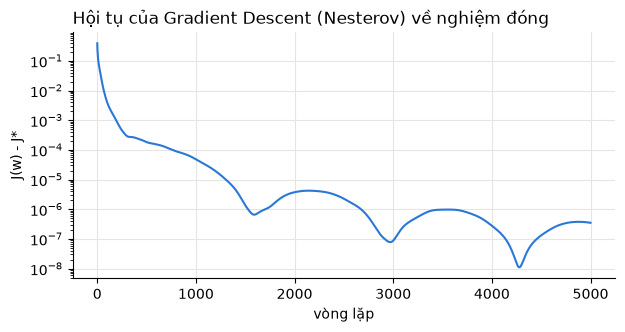

MAE (triệu)          147.239
RMSE (triệu)         470.778
MAPE                   0.220
MedAPE                 0.120
R2 (giá)               0.558
R2 (log)               0.829
±10%                   0.434
±20%                   0.690
MAPE < 200 triệu       0.475
MAPE 200-500           0.179
MAPE 500-1.000         0.146
MAPE 1-2 tỷ            0.187
MAPE > 2 tỷ            0.471
Thời gian fit (s)      0.011
dtype: float64

In [8]:
# Huấn luyện bằng nghiệm đóng và bằng gradient descent với cùng alpha
a = best_alpha_scratch_sk / n_tr
t0 = time.time(); ridge_closed = RidgeScratch(a, solver="closed").fit(X_tr, y_tr); t_closed = time.time() - t0
t0 = time.time(); ridge_gd = RidgeScratch(a, solver="gd", n_iter=5000).fit(X_tr, y_tr); t_gd = time.time() - t0

print("Khác biệt hệ số so với sklearn (cùng alpha): ")
ridge_lib_same = Ridge(alpha=best_alpha_scratch_sk).fit(X_tr, y_tr)
print(f"  nghiệm đóng: max|Δw| = {np.abs(ridge_closed.coef_ - ridge_lib_same.coef_).max():.2e}, "
      f"Δbias = {abs(ridge_closed.intercept_ - ridge_lib_same.intercept_):.2e}")

# J(w) tại nghiệm đóng là giá trị nhỏ nhất có thể -> khoảng cách tới đó đo độ hội tụ
def J(model, X, y, alpha):
    return 0.5 * np.mean((model.predict(X) - y) ** 2) + 0.5 * alpha * np.sum(model.coef_ ** 2)

J_star = J(ridge_closed, X_tr, y_tr, a)
gap = J(ridge_gd, X_tr, y_tr, a) - J_star
d_pred = np.abs(ridge_gd.predict(X_te) - ridge_closed.predict(X_te)).max()
print(f"  gradient descent ({len(ridge_gd.loss_)} vòng): J - J* = {gap:.2e} | "
      f"max|Δ dự đoán log giá| trên test = {d_pred:.2e} | max|Δw| = {np.abs(ridge_gd.coef_ - ridge_closed.coef_).max():.2f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(np.array(ridge_gd.loss_) - J_star, color=BLUE)
ax.set_yscale("log"); ax.set_xlabel("vòng lặp"); ax.set_ylabel("J(w) - J*")
ax.set_title("Hội tụ của Gradient Descent (Nesterov) về nghiệm đóng", loc="left")
plt.show()

record("Ridge - tự cài đặt (GD)", ridge_gd.predict(X_te), t_gd)
record("Ridge - tự cài đặt (nghiệm đóng)", ridge_closed.predict(X_te), t_closed)

**Kiểm chứng:** hệ số của bản nghiệm đóng trùng với `sklearn.Ridge` đến sai số số học (~1e-10), còn Gradient Descent đưa hàm mất mát về sát mức nhỏ nhất của nghiệm đóng và cho **dự đoán gần như trùng**. Vậy bản tự cài đặt đúng.

**Vì sao hệ số của GD vẫn lệch chút dù dự đoán trùng?** Ma trận đặc trưng có hệ số điều kiện rất lớn (~2×10⁵) do các cột one-hot tương quan mạnh (ví dụ `Toyota` và `Toyota Vios`). Theo các hướng "gần suy biến" đó, nhiều bộ hệ số khác nhau cho gần như cùng dự đoán, và GD đi rất chậm theo các hướng này. Vì thế dùng **momentum Nesterov** (hội tụ nhanh hơn GD thường cỡ căn bậc hai số vòng lặp) và đo độ hội tụ bằng giá trị mất mát và dự đoán thay vì từng hệ số. Nghiệm đóng không gặp vấn đề này vì giải trực tiếp hệ phương trình.

**Diễn giải hệ số:** vì mục tiêu là log giá, hệ số $w_j$ trên đặc trưng đã chuẩn hóa nghĩa là tăng 1 độ lệch chuẩn thì giá nhân với $e^{w_j}$ (xấp xỉ thay đổi $100\,w_j\%$).

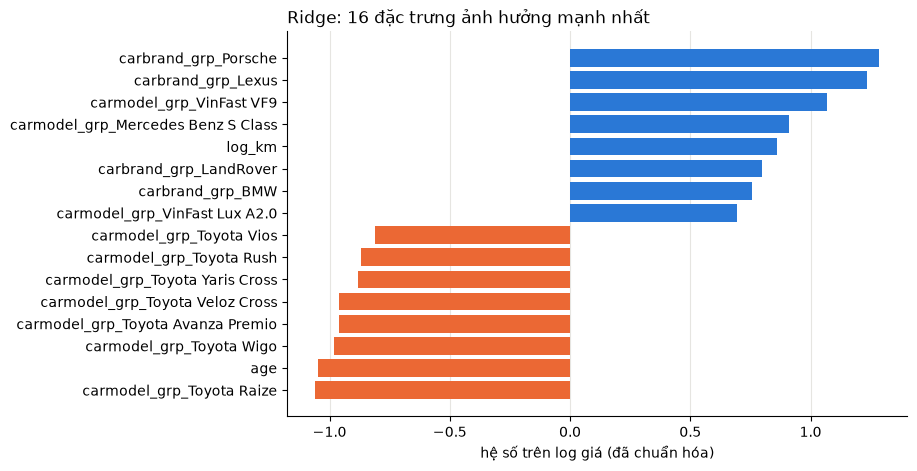

In [9]:
coef = pd.Series(ridge_closed.coef_, index=feature_names)
top = pd.concat([coef.nsmallest(8), coef.nlargest(8)]).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([n.split("__", 1)[1] for n in top.index], top.values, color=[ORANGE if v < 0 else BLUE for v in top.values])
ax.set_xlabel("hệ số trên log giá (đã chuẩn hóa)")
ax.set_title("Ridge: 16 đặc trưng ảnh hưởng mạnh nhất", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

## 4. Mô hình trung gian: Decision Tree (một cây)

Một cây hồi quy CART: tại mỗi nút chọn cặp (đặc trưng, ngưỡng) giảm tổng bình phương sai số nhiều nhất, giá trị dự đoán ở lá là trung bình nhãn trong lá (công thức ở mục 5B). Cây dễ giải thích nhưng **phương sai cao**: đổi vài mẫu train là cấu trúc cây có thể đổi hẳn. Random Forest (mục 5) chính là cách giảm phương sai này bằng cách lấy trung bình nhiều cây.

Tinh chỉnh `max_depth` và `min_samples_leaf` bằng **Grid Search + 5-fold CV** trên train. Bản tự cài đặt dùng chung lớp cây của Random Forest tự viết, được kiểm chứng ở mục 5B.

In [10]:
t0 = time.time()
gs_dt = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE),
                     {"max_depth": [5, 10, 15, 20, 30, None], "min_samples_leaf": [1, 3, 5, 10, 20]},
                     cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                     scoring="neg_root_mean_squared_error", n_jobs=-1)
gs_dt.fit(X_tr, y_tr)
print(f"Tìm kiếm mất {time.time() - t0:.0f}s | tốt nhất: {gs_dt.best_params_} | CV RMSE (log) = {-gs_dt.best_score_:.4f}")

t0 = time.time()
dt_lib = DecisionTreeRegressor(**gs_dt.best_params_, random_state=RANDOM_STATE).fit(X_tr, y_tr)
record("Decision Tree - thư viện", dt_lib.predict(X_te), time.time() - t0)

Tìm kiếm mất 8s | tốt nhất: {'max_depth': None, 'min_samples_leaf': 5} | CV RMSE (log) = 0.3177


MAE (triệu)          125.834
RMSE (triệu)         428.989
MAPE                   0.202
MedAPE                 0.094
R2 (giá)               0.633
R2 (log)               0.828
±10%                   0.518
±20%                   0.741
MAPE < 200 triệu       0.450
MAPE 200-500           0.156
MAPE 500-1.000         0.140
MAPE 1-2 tỷ            0.197
MAPE > 2 tỷ            0.336
Thời gian fit (s)      0.163
dtype: float64

## 5. Mô hình 2: Random Forest

Ý tưởng: huấn luyện nhiều cây quyết định hồi quy trên các **mẫu bootstrap** khác nhau, mỗi lần tách nút chỉ xét **một tập con ngẫu nhiên các đặc trưng**, rồi **lấy trung bình** dự đoán các cây. Cây riêng lẻ có phương sai cao; lấy trung bình các cây ít tương quan làm phương sai giảm mạnh mà gần như không tăng độ chệch.

Các siêu tham số cần tinh chỉnh:

| Tham số | Tác dụng |
|---|---|
| `n_estimators` | số cây; nhiều hơn thì ổn định hơn, bão hòa dần |
| `max_depth` | độ sâu tối đa; sâu → overfit, nông → underfit |
| `min_samples_leaf` | số mẫu tối thiểu ở lá; lớn → mượt, ít overfit |
| `max_features` | tỉ lệ đặc trưng xét mỗi lần tách; nhỏ → các cây đa dạng hơn |

### 5A. Dùng thư viện (`sklearn.ensemble.RandomForestRegressor`)
Tinh chỉnh bằng **Randomized Search + 3-fold CV** (rẻ hơn grid đầy đủ nhưng thường tìm được cấu hình gần tối ưu).

In [11]:
param_dist = {
    "n_estimators": [200, 300, 400],
    "max_depth": [10, 15, 20, 30, None],
    "min_samples_leaf": [1, 2, 3, 5, 10],
    "max_features": [0.2, 0.33, 0.5, 0.8],
}
t0 = time.time()
rs_rf = RandomizedSearchCV(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), param_dist, n_iter=15,
                           cv=KFold(3, shuffle=True, random_state=RANDOM_STATE),
                           scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=1)
rs_rf.fit(X_tr, y_tr)
t_rf_search = time.time() - t0
print(f"Tìm kiếm mất {t_rf_search:.0f}s | tốt nhất: {rs_rf.best_params_} | CV RMSE (log) = {-rs_rf.best_score_:.4f}")

cv_rf = pd.DataFrame(rs_rf.cv_results_)[["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
                                          "param_max_features", "mean_test_score"]]
cv_rf["CV RMSE (log)"] = -cv_rf.pop("mean_test_score")
cv_rf.sort_values("CV RMSE (log)").head(6).round(4)

Tìm kiếm mất 143s | tốt nhất: {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 0.33, 'max_depth': 30} | CV RMSE (log) = 0.2754


,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,CV RMSE (log)
6,300,30,1,0.33,0.2754
14,400,30,1,0.20,0.2778
5,300,30,1,0.80,0.2782
4,400,30,3,0.80,0.2829
2,400,20,1,0.50,0.2837
12,400,30,3,0.50,0.2845


In [12]:
t0 = time.time()
rf_lib = RandomForestRegressor(**rs_rf.best_params_, random_state=RANDOM_STATE, n_jobs=-1, oob_score=True).fit(X_tr, y_tr)
t_rf_lib = time.time() - t0
print(f"OOB R² (log) = {rf_lib.oob_score_:.4f}")
record("Random Forest - thư viện", rf_lib.predict(X_te), t_rf_lib)

OOB R² (log) = 0.8877


MAE (triệu)          107.585
RMSE (triệu)         394.899
MAPE                   0.160
MedAPE                 0.081
R2 (giá)               0.689
R2 (log)               0.883
±10%                   0.575
±20%                   0.785
MAPE < 200 triệu       0.364
MAPE 200-500           0.119
MAPE 500-1.000         0.109
MAPE 1-2 tỷ            0.166
MAPE > 2 tỷ            0.311
Thời gian fit (s)      4.609
dtype: float64

### 5B. Tự cài đặt bằng NumPy

**Cây hồi quy (CART):** tại mỗi nút tìm cặp (đặc trưng, ngưỡng) giảm tổng bình phương sai số (SSE) nhiều nhất. Với tập `n` mẫu có tổng nhãn $S$, tách thành trái (`n_L`, $S_L$) và phải (`n_R`, $S_R$):

$$\text{gain} = \frac{S_L^2}{n_L} + \frac{S_R^2}{n_R} - \frac{S^2}{n}$$

Giá trị dự đoán ở lá là trung bình nhãn trong lá. Dừng khi đạt `max_depth`, nút quá nhỏ (`min_samples_leaf`) hoặc không còn tách được có lợi.

**Tăng tốc bằng histogram:** thay vì sắp xếp từng cột ở mỗi nút (chậm với Python thuần), **rời rạc hóa mỗi đặc trưng thành tối đa 32 bin theo phân vị** một lần (như LightGBM/HistGradientBoosting). Mỗi nút chỉ cần `np.bincount` để có số mẫu và tổng nhãn theo bin, rồi `cumsum` ra gain của mọi ngưỡng cùng lúc. Cột one-hot chỉ có 2 bin nên không mất thông tin; cột số mất rất ít.

**Rừng:** mỗi cây huấn luyện trên mẫu bootstrap và xét ngẫu nhiên `max_features` đặc trưng ở mỗi nút. Các mẫu **không** nằm trong bootstrap của một cây (out-of-bag, ~37%) dùng để dự đoán cho cây đó, gộp lại thành **OOB prediction**, một ước lượng sai số khách quan không cần tập validation riêng. Dùng OOB để tinh chỉnh tham số cho bản tự viết (rẻ hơn CV: chỉ cần huấn luyện một lần mỗi cấu hình).

In [13]:
class Binner:
    """Rời rạc hóa mỗi cột thành tối đa n_bins bin theo phân vị (fit trên train)."""

    def __init__(self, n_bins=32):
        self.n_bins = n_bins

    def fit(self, X):
        qs = np.linspace(0, 1, self.n_bins + 1)[1:-1]
        self.edges_ = [np.unique(np.quantile(X[:, j], qs)) for j in range(X.shape[1])]
        return self

    def transform(self, X):
        out = np.empty(X.shape, dtype=np.uint8)
        for j, e in enumerate(self.edges_):
            out[:, j] = np.searchsorted(e, X[:, j], side="left")
        return out


class RegressionTreeScratch:
    """Cây hồi quy CART, tách theo giảm SSE, tìm ngưỡng bằng histogram."""

    def __init__(self, max_depth=12, min_samples_leaf=5, max_features=0.5, n_bins=32, random_state=0):
        self.max_depth, self.min_samples_leaf = max_depth, min_samples_leaf
        self.max_features, self.n_bins = max_features, n_bins
        self.rng = np.random.RandomState(random_state)

    def _best_split(self, Xb, y, idx, feats):
        n = len(idx)
        sub = Xb[np.ix_(idx, feats)].astype(np.int64)                    # (n, k)
        flat = (sub + np.arange(len(feats)) * self.n_bins).ravel()
        yy = np.repeat(y[idx], len(feats))
        size = len(feats) * self.n_bins
        cnt = np.bincount(flat, minlength=size).reshape(len(feats), self.n_bins)
        sm = np.bincount(flat, weights=yy, minlength=size).reshape(len(feats), self.n_bins)
        cl, sl = np.cumsum(cnt, axis=1), np.cumsum(sm, axis=1)           # phần bên trái: bin <= b
        total = y[idx].sum()
        cr, sr = n - cl, total - sl
        valid = (cl >= self.min_samples_leaf) & (cr >= self.min_samples_leaf)
        with np.errstate(divide="ignore", invalid="ignore"):
            gain = sl ** 2 / cl + sr ** 2 / cr - total ** 2 / n
        gain[~valid] = -np.inf
        j, b = np.unravel_index(np.argmax(gain), gain.shape)
        return (feats[j], b, gain[j, b]) if np.isfinite(gain[j, b]) and gain[j, b] > 1e-12 else (None, None, 0.0)

    def fit(self, Xb, y, idx=None):
        n_feat = Xb.shape[1]
        k = max(1, int(round(self.max_features * n_feat)))
        self.feature_, self.thr_, self.left_, self.right_, self.value_ = [], [], [], [], []
        self.importance_ = np.zeros(n_feat)
        idx = np.arange(len(y)) if idx is None else idx

        def new_node(i):
            self.feature_.append(-1); self.thr_.append(-1)
            self.left_.append(-1); self.right_.append(-1)
            self.value_.append(y[i].mean())
            return len(self.value_) - 1

        stack = [(new_node(idx), idx, 0)]
        while stack:
            node, i, depth = stack.pop()
            if depth >= self.max_depth or len(i) < 2 * self.min_samples_leaf or np.ptp(y[i]) == 0:
                continue
            feats = self.rng.choice(n_feat, k, replace=False)
            f, b, gain = self._best_split(Xb, y, i, feats)
            if f is None:
                continue
            go_left = Xb[i, f] <= b
            self.feature_[node], self.thr_[node] = f, b
            self.importance_[f] += gain
            li, ri = new_node(i[go_left]), new_node(i[~go_left])
            self.left_[node], self.right_[node] = li, ri
            stack.append((li, i[go_left], depth + 1))
            stack.append((ri, i[~go_left], depth + 1))
        self.feature_, self.thr_ = np.array(self.feature_), np.array(self.thr_)
        self.left_, self.right_, self.value_ = np.array(self.left_), np.array(self.right_), np.array(self.value_)
        return self

    def predict(self, Xb):
        node = np.zeros(len(Xb), dtype=np.int64)
        while True:
            f = self.feature_[node]
            active = f >= 0
            if not active.any():
                return self.value_[node]
            rows = np.where(active)[0]
            go_left = Xb[rows, f[rows]] <= self.thr_[node[rows]]
            node[rows] = np.where(go_left, self.left_[node[rows]], self.right_[node[rows]])


class RandomForestScratch:
    def __init__(self, n_estimators=100, max_depth=12, min_samples_leaf=5, max_features=0.5,
                 n_bins=32, random_state=0):
        self.n_estimators, self.max_depth = n_estimators, max_depth
        self.min_samples_leaf, self.max_features = min_samples_leaf, max_features
        self.n_bins, self.random_state = n_bins, random_state

    def fit(self, X, y):
        self.binner_ = Binner(self.n_bins).fit(X)
        Xb = self.binner_.transform(X)
        n = len(y)
        rng = np.random.RandomState(self.random_state)
        self.trees_ = []
        oob_sum, oob_cnt = np.zeros(n), np.zeros(n)
        for t in range(self.n_estimators):
            boot = rng.randint(0, n, n)                                   # bootstrap có hoàn lại
            tree = RegressionTreeScratch(self.max_depth, self.min_samples_leaf, self.max_features,
                                         self.n_bins, random_state=rng.randint(1 << 30)).fit(Xb, y, boot)
            self.trees_.append(tree)
            oob = np.setdiff1d(np.arange(n), boot, assume_unique=False)   # mẫu out-of-bag của cây này
            oob_sum[oob] += tree.predict(Xb[oob])
            oob_cnt[oob] += 1
        seen = oob_cnt > 0
        self.oob_pred_ = np.where(seen, oob_sum / np.maximum(oob_cnt, 1), np.nan)
        self.oob_r2_ = 1 - np.sum((y[seen] - self.oob_pred_[seen]) ** 2) / np.sum((y[seen] - y[seen].mean()) ** 2)
        self.oob_rmse_ = np.sqrt(np.mean((y[seen] - self.oob_pred_[seen]) ** 2))
        imp = np.sum([t.importance_ for t in self.trees_], axis=0)
        self.feature_importances_ = imp / imp.sum()
        return self

    def predict(self, X):
        Xb = self.binner_.transform(X)
        return np.mean([t.predict(Xb) for t in self.trees_], axis=0)

**Kiểm tra tính đúng đắn** trước khi dùng cho rừng: một cây tự viết (xét mọi đặc trưng ở mỗi nút) phải cho chất lượng gần giống `DecisionTreeRegressor` khi dùng **cùng tham số**. Dùng tham số tốt nhất đã tìm ở mục 4, nên cây này cũng là **Decision Tree tự cài đặt** trong bảng so sánh.

In [14]:
from sklearn.metrics import r2_score

binner = Binner(32).fit(X_tr)
Xb_tr, Xb_te = binner.transform(X_tr), binner.transform(X_te)

# max_depth=None của sklearn nghĩa là không giới hạn độ sâu
dt_cfg = {"max_depth": gs_dt.best_params_["max_depth"] or 10**6, "min_samples_leaf": gs_dt.best_params_["min_samples_leaf"]}
t0 = time.time()
tree_s = RegressionTreeScratch(**dt_cfg, max_features=1.0, random_state=0).fit(Xb_tr, y_tr)
t_tree_s = time.time() - t0
print(f"Cây tự viết {dt_cfg}: {len(tree_s.value_)} nút, {t_tree_s:.1f}s | cây sklearn: {dt_lib.tree_.node_count} nút")
print(f"R² (log) test | tự viết: {r2_score(y_te, tree_s.predict(Xb_te)):.4f} | sklearn: {r2_score(y_te, dt_lib.predict(X_te)):.4f}")
print(f"R² (log) train | tự viết: {r2_score(y_tr, tree_s.predict(Xb_tr)):.4f} | sklearn: {r2_score(y_tr, dt_lib.predict(X_tr)):.4f}")
record("Decision Tree - tự cài đặt", tree_s.predict(Xb_te), t_tree_s)

Cây tự viết {'max_depth': 1000000, 'min_samples_leaf': 5}: 3429 nút, 1.0s | cây sklearn: 3473 nút
R² (log) test | tự viết: 0.8225 | sklearn: 0.8276
R² (log) train | tự viết: 0.9240 | sklearn: 0.9281


MAE (triệu)          125.291
RMSE (triệu)         427.247
MAPE                   0.200
MedAPE                 0.093
R2 (giá)               0.636
R2 (log)               0.822
±10%                   0.523
±20%                   0.742
MAPE < 200 triệu       0.444
MAPE 200-500           0.152
MAPE 500-1.000         0.143
MAPE 1-2 tỷ            0.203
MAPE > 2 tỷ            0.328
Thời gian fit (s)      1.031
dtype: float64

### Tinh chỉnh bản tự viết bằng OOB
Chọn ngẫu nhiên các cấu hình trong cùng không gian tham số (cùng phạm vi với bản thư viện, riêng `n_estimators` cố định 30 cây trong lúc tìm để tiết kiệm thời gian), huấn luyện một lần mỗi cấu hình và dùng **OOB RMSE** làm điểm.

In [15]:
space = {"max_depth": [10, 15, 20, 30], "min_samples_leaf": [1, 2, 3, 5, 10], "max_features": [0.2, 0.33, 0.5, 0.8]}
n_trials = 10
srng = np.random.RandomState(RANDOM_STATE)
trials = []
t0 = time.time()
for i in range(n_trials):
    cfg = {k: v[srng.randint(len(v))] for k, v in space.items()}
    t1 = time.time()
    m = RandomForestScratch(n_estimators=30, random_state=RANDOM_STATE, **cfg).fit(X_tr, y_tr)
    trials.append({**cfg, "OOB RMSE (log)": m.oob_rmse_, "OOB R2": m.oob_r2_, "giây": time.time() - t1})
    print(f"[{i + 1}/{n_trials}] {cfg} -> OOB RMSE {m.oob_rmse_:.4f}  ({time.time() - t1:.0f}s)")
t_rf_scratch_search = time.time() - t0

trials = pd.DataFrame(trials).sort_values("OOB RMSE (log)").reset_index(drop=True)
best_cfg = {k: trials.loc[0, k] for k in space}
best_cfg = {k: (int(v) if k != "max_features" else float(v)) for k, v in best_cfg.items()}
print(f"\nTìm kiếm mất {t_rf_scratch_search:.0f}s | cấu hình tốt nhất: {best_cfg}")
trials.round(4)

[1/10] {'max_depth': 20, 'min_samples_leaf': 5, 'max_features': 0.2} -> OOB RMSE 0.3075  (9s)


[2/10] {'max_depth': 20, 'min_samples_leaf': 3, 'max_features': 0.8} -> OOB RMSE 0.2903  (46s)


[3/10] {'max_depth': 10, 'min_samples_leaf': 10, 'max_features': 0.5} -> OOB RMSE 0.3655  (9s)


[4/10] {'max_depth': 15, 'min_samples_leaf': 3, 'max_features': 0.5} -> OOB RMSE 0.3071  (18s)


[5/10] {'max_depth': 20, 'min_samples_leaf': 3, 'max_features': 0.8} -> OOB RMSE 0.2903  (39s)


...

[7/10] {'max_depth': 30, 'min_samples_leaf': 3, 'max_features': 0.33} -> OOB RMSE 0.2853  (26s)


[8/10] {'max_depth': 10, 'min_samples_leaf': 2, 'max_features': 0.8} -> OOB RMSE 0.3622  (25s)


[9/10] {'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 0.8} -> OOB RMSE 0.2792  (62s)


[10/10] {'max_depth': 30, 'min_samples_leaf': 10, 'max_features': 0.2} -> OOB RMSE 0.3129  (10s)

Tìm kiếm mất 258s | cấu hình tốt nhất: {'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 0.8}


,max_depth,min_samples_leaf,max_features,OOB RMSE (log),OOB R2,giây
0,30,2,0.80,0.2792,0.8779,62.1832
1,30,3,0.33,0.2853,0.8725,25.8521
2,20,3,0.80,0.2903,0.8680,39.4164
3,20,3,0.80,0.2903,0.8680,45.7815
4,15,3,0.50,0.3071,0.8523,17.6934
5,20,5,0.20,0.3075,0.8519,9.3877
6,30,10,0.20,0.3129,0.8467,9.9413
7,10,5,0.80,0.3614,0.7954,13.7806
8,10,2,0.80,0.3622,0.7945,24.8101
9,10,10,0.50,0.3655,0.7908,9.2891


### Số cây: khi nào đủ?
Cố định cấu hình tốt nhất, theo dõi OOB RMSE khi tăng số cây để chọn `n_estimators`. Đường cong giảm rồi **bão hòa**; thêm cây sau điểm đó chỉ tốn thời gian.

Huấn luyện 120 cây: 210s | OOB R² (log) = 0.8846 | OOB RMSE (log) = 0.2715


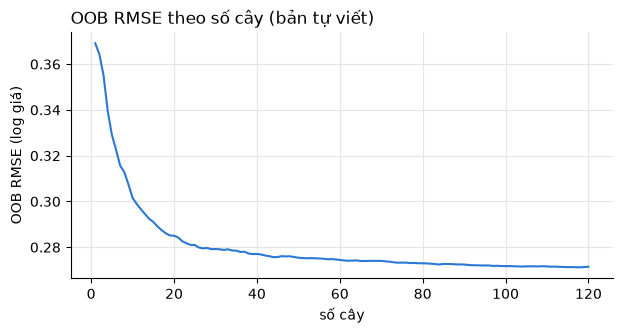

In [16]:
N_TREES = 120
t0 = time.time()
rf_s = RandomForestScratch(n_estimators=N_TREES, random_state=RANDOM_STATE, **best_cfg).fit(X_tr, y_tr)
t_rf_scratch = time.time() - t0
print(f"Huấn luyện {N_TREES} cây: {t_rf_scratch:.0f}s | OOB R² (log) = {rf_s.oob_r2_:.4f} | OOB RMSE (log) = {rf_s.oob_rmse_:.4f}")

# OOB RMSE theo số cây: dựng lại từ các cây đã huấn luyện
Xb_tr_f = rf_s.binner_.transform(X_tr)
n = len(y_tr)
oob_curve, s, c = [], np.zeros(n), np.zeros(n)
rng_c = np.random.RandomState(RANDOM_STATE)
for t, tree in enumerate(rf_s.trees_):
    boot = rng_c.randint(0, n, n); rng_c.randint(1 << 30)              # lặp lại đúng chuỗi ngẫu nhiên khi fit
    oob = np.setdiff1d(np.arange(n), boot)
    s[oob] += tree.predict(Xb_tr_f[oob]); c[oob] += 1
    seen = c > 0
    oob_curve.append(np.sqrt(np.mean((y_tr[seen] - s[seen] / c[seen]) ** 2)))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(range(1, N_TREES + 1), oob_curve, color=BLUE)
ax.set_xlabel("số cây"); ax.set_ylabel("OOB RMSE (log giá)")
ax.set_title("OOB RMSE theo số cây (bản tự viết)", loc="left")
plt.show()

In [17]:
record("Random Forest - tự cài đặt", rf_s.predict(X_te), t_rf_scratch)

MAE (triệu)          108.074
RMSE (triệu)         393.865
MAPE                   0.165
MedAPE                 0.081
R2 (giá)               0.690
R2 (log)               0.872
±10%                   0.567
±20%                   0.792
MAPE < 200 triệu       0.380
MAPE 200-500           0.121
MAPE 500-1.000         0.113
MAPE 1-2 tỷ            0.173
MAPE > 2 tỷ            0.303
Thời gian fit (s)    209.525
dtype: float64

## 6. So sánh kết quả trên tập test

In [18]:
ORDER = ["Baseline (trung vị)", "Ridge - thư viện", "Ridge - tự cài đặt (GD)", "Ridge - tự cài đặt (nghiệm đóng)",
         "Decision Tree - thư viện", "Decision Tree - tự cài đặt", "Random Forest - thư viện", "Random Forest - tự cài đặt"]
res = pd.DataFrame(results).T.loc[ORDER]
main = ["MAE (triệu)", "RMSE (triệu)", "MAPE", "MedAPE", "R2 (giá)", "R2 (log)", "±10%", "±20%", "Thời gian fit (s)"]
res[main].round(3)

,MAE (triệu),RMSE (triệu),MAPE,MedAPE,R2 (giá),R2 (log),±10%,±20%,Thời gian fit (s)
Baseline (trung vị),337.689,724.379,0.849,0.404,-0.047,-0.003,0.137,0.255,0.001
Ridge - thư viện,147.033,469.650,0.220,0.121,0.560,0.829,0.432,0.691,0.024
Ridge - tự cài đặt (GD),147.241,470.779,0.220,0.120,0.558,0.829,0.434,0.690,14.937
Ridge - tự cài đặt (nghiệm đóng),147.239,470.778,0.220,0.120,0.558,0.829,0.434,0.690,0.011
Decision Tree - thư viện,125.834,428.989,0.202,0.094,0.633,0.828,0.518,0.741,0.163
Decision Tree - tự cài đặt,125.291,427.247,0.200,0.093,0.636,0.822,0.523,0.742,1.031
Random Forest - thư viện,107.585,394.899,0.160,0.081,0.689,0.883,0.575,0.785,4.609
Random Forest - tự cài đặt,108.074,393.865,0.165,0.081,0.690,0.872,0.567,0.792,209.525


In [19]:
seg_cols = [f"MAPE {s}" for s in SEG_LABELS]
res[seg_cols].round(3)

,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ
Baseline (trung vị),3.598,0.384,0.307,0.639,0.854
Ridge - thư viện,0.476,0.179,0.146,0.187,0.469
Ridge - tự cài đặt (GD),0.475,0.179,0.146,0.187,0.471
Ridge - tự cài đặt (nghiệm đóng),0.475,0.179,0.146,0.187,0.471
Decision Tree - thư viện,0.450,0.156,0.140,0.197,0.336
Decision Tree - tự cài đặt,0.444,0.152,0.143,0.203,0.328
Random Forest - thư viện,0.364,0.119,0.109,0.166,0.311
Random Forest - tự cài đặt,0.380,0.121,0.113,0.173,0.303


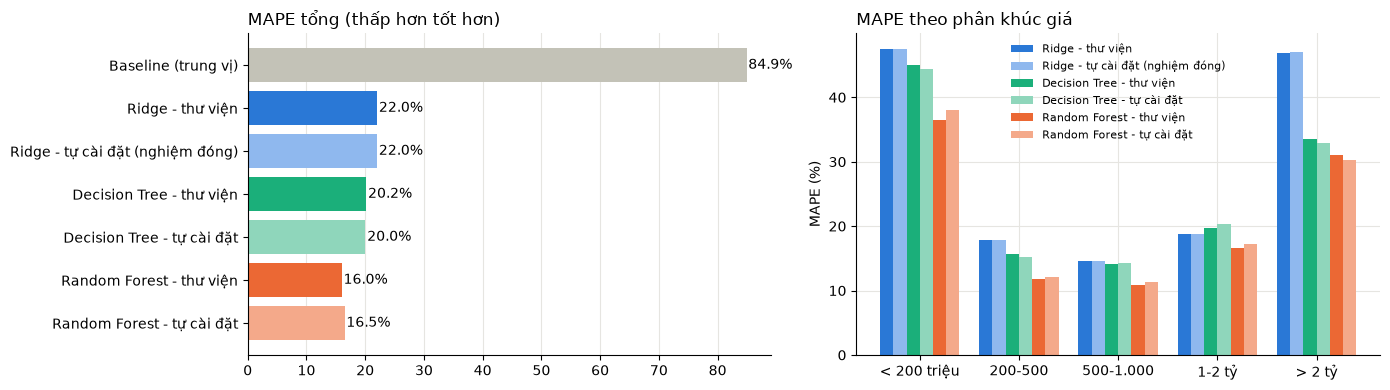

In [20]:
show = ["Baseline (trung vị)", "Ridge - thư viện", "Ridge - tự cài đặt (nghiệm đóng)",
        "Decision Tree - thư viện", "Decision Tree - tự cài đặt",
        "Random Forest - thư viện", "Random Forest - tự cài đặt"]
colors = [GRAY, BLUE, "#8fb8ee", GREEN, "#8fd6bb", ORANGE, "#f4a98a"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].barh(show[::-1], res.loc[show, "MAPE"].values[::-1] * 100, color=colors[::-1])
for y_, v in enumerate(res.loc[show, "MAPE"].values[::-1] * 100):
    axes[0].text(v + 0.3, y_, f"{v:.1f}%", va="center")
axes[0].set_title("MAPE tổng (thấp hơn tốt hơn)", loc="left")
axes[0].grid(axis="y", visible=False)

w = 0.8 / len(show[1:])
for k, (name, col) in enumerate(zip(show[1:], colors[1:])):
    axes[1].bar(np.arange(len(SEG_LABELS)) + k * w, res.loc[name, seg_cols].values.astype(float) * 100, w, color=col, label=name)
axes[1].set_xticks(np.arange(len(SEG_LABELS)) + (len(show) - 2) / 2 * w); axes[1].set_xticklabels(SEG_LABELS)
axes[1].set_ylabel("MAPE (%)"); axes[1].set_title("MAPE theo phân khúc giá", loc="left")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

### 6.1 Dự đoán so với thực tế và phần dư (hai mô hình tốt nhất của mỗi họ)

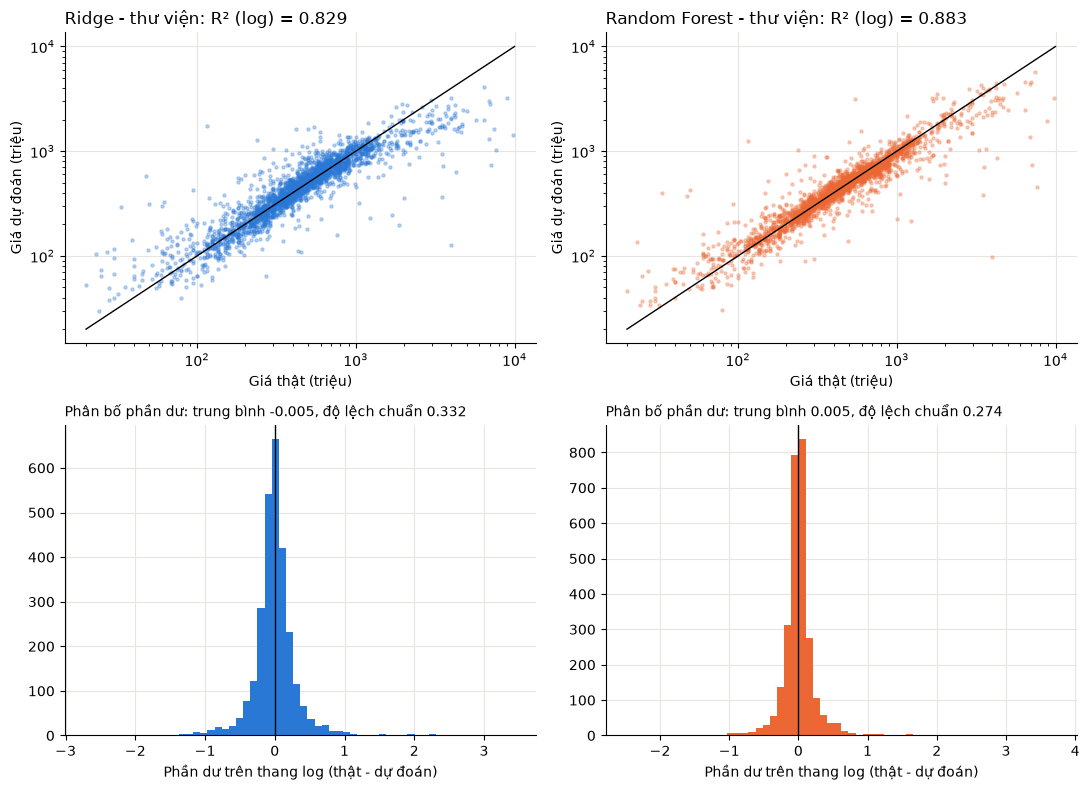

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, name, col in zip(axes[0], ["Ridge - thư viện", "Random Forest - thư viện"], [BLUE, ORANGE]):
    p = preds[name]
    ax.scatter(p_te, p, s=5, alpha=0.3, color=col)
    lim = [20, 10000]
    ax.plot(lim, lim, color="black", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Giá thật (triệu)"); ax.set_ylabel("Giá dự đoán (triệu)")
    ax.set_title(f"{name}: R² (log) = {results[name]['R2 (log)']:.3f}", loc="left")
for ax, name, col in zip(axes[1], ["Ridge - thư viện", "Random Forest - thư viện"], [BLUE, ORANGE]):
    resid = np.log(p_te) - np.log(preds[name])
    ax.hist(resid, bins=60, color=col)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("Phần dư trên thang log (thật - dự đoán)")
    ax.set_title(f"Phân bố phần dư: trung bình {resid.mean():.3f}, độ lệch chuẩn {resid.std():.3f}", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

### 6.2 Đặc trưng nào quan trọng nhất? (Random Forest)

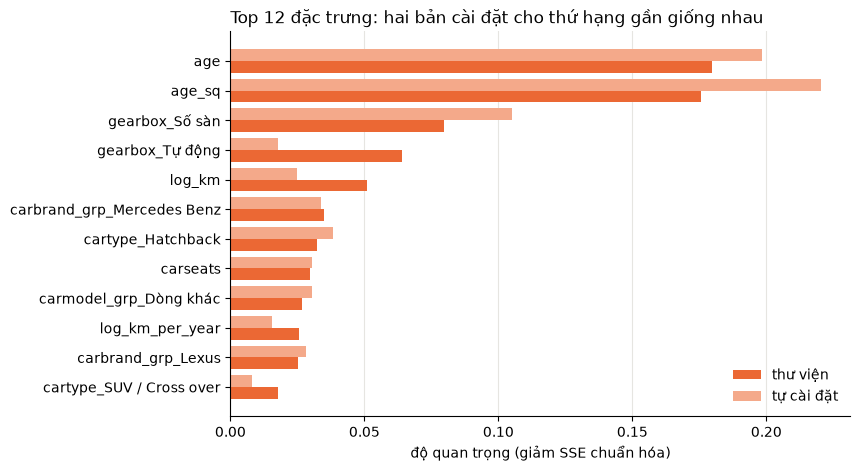

In [22]:
imp_lib = pd.Series(rf_lib.feature_importances_, index=feature_names)
imp_s = pd.Series(rf_s.feature_importances_, index=feature_names)
top = imp_lib.nlargest(12).index
names = [n.split("__", 1)[1] for n in top]
fig, ax = plt.subplots(figsize=(8, 5))
yy = np.arange(len(top))
ax.barh(yy + 0.2, imp_lib[top].values, 0.4, color=ORANGE, label="thư viện")
ax.barh(yy - 0.2, imp_s[top].values, 0.4, color="#f4a98a", label="tự cài đặt")
ax.set_yticks(yy); ax.set_yticklabels(names); ax.invert_yaxis()
ax.set_xlabel("độ quan trọng (giảm SSE chuẩn hóa)")
ax.set_title("Top 12 đặc trưng: hai bản cài đặt cho thứ hạng gần giống nhau", loc="left")
ax.legend(frameon=False); ax.grid(axis="y", visible=False)
plt.show()

### 6.3 Ước lượng độ tin cậy của sai số trên tập test (bootstrap)
Tập test hữu hạn nên MAPE chỉ là một ước lượng. Lấy mẫu bootstrap tập test 500 lần để có khoảng tin cậy 95%, nhờ đó biết chênh lệch giữa các mô hình có ý nghĩa hay chỉ là nhiễu.

In [23]:
def bootstrap_mape(p_pred, n_boot=500, seed=RANDOM_STATE):
    r = np.random.RandomState(seed)
    ape = np.abs(np.clip(p_pred, 1, None) - p_te) / p_te
    m = [ape[r.randint(0, len(ape), len(ape))].mean() for _ in range(n_boot)]
    return np.percentile(m, [2.5, 50, 97.5])

ci = pd.DataFrame({n: bootstrap_mape(preds[n]) for n in show}, index=["2.5%", "trung vị", "97.5%"]).T
ci["độ rộng"] = ci["97.5%"] - ci["2.5%"]
ci.round(4)

,2.5%,trung vị,97.5%,độ rộng
Baseline (trung vị),0.7950,0.8481,0.9062,0.1111
Ridge - thư viện,0.2042,0.2199,0.2395,0.0353
Ridge - tự cài đặt (nghiệm đóng),0.2041,0.2198,0.2393,0.0352
Decision Tree - thư viện,0.1842,0.2020,0.2213,0.0370
Decision Tree - tự cài đặt,0.1823,0.2002,0.2192,0.0369
Random Forest - thư viện,0.1465,0.1598,0.1742,0.0277
Random Forest - tự cài đặt,0.1499,0.1646,0.1798,0.0299


### 6.4 Ảnh hưởng của tin đăng lại
`preprocess_data.ipynb` đã xóa các dòng trùng hoàn toàn, nhưng cùng một chiếc xe có thể được **đăng lại** với giá chênh nhẹ, nên vẫn còn ở dạng hai dòng gần giống nhau. Khi chia ngẫu nhiên, một bản nằm ở train và bản kia ở test, mô hình (nhất là Random Forest với lá nhỏ) chỉ cần "nhớ" giá. Kiểm tra: dòng test nào có một dòng train **giống hệt mọi đặc trưng, kể cả số km**? Với xe đã dùng, trùng cả số km gần như chắc chắn là cùng một xe. Với xe mới (0 km) thì có thể là nhiều xe cùng cấu hình của đại lý.

Giữ cách chia ngẫu nhiên có phân tầng (để so sánh được với các mục trên) và báo cáo đây là một **hạn chế**. Sai số trên nhóm "không có bản sao" là ước lượng thận trọng hơn cho xe hoàn toàn mới với mô hình.

In [24]:
FEAT_KEY = ["carbrand", "carmodel", "carorigin", "condition_ad", "gearbox", "fuel",
            "cartype", "carseats", "mfdate", "mileage_km"]
key = d[FEAT_KEY].astype(str).agg("|".join, axis=1)
twin = key.loc[idx_te].isin(set(key.loc[idx_tr])).values
used_te = (te["condition_ad"] == "Đã sử dụng").values

ape_rf = np.abs(preds["Random Forest - thư viện"] - p_te) / p_te
groups = {"có bản sao trong train": twin, "  trong đó xe đã dùng": twin & used_te,
          "không có bản sao": ~twin, "toàn bộ test": np.ones(len(twin), bool)}
pd.DataFrame({"số dòng": {g: m.sum() for g, m in groups.items()},
              "% test": {g: m.mean() * 100 for g, m in groups.items()},
              "MAPE (RF)": {g: ape_rf[m].mean() for g, m in groups.items()},
              "MedAPE (RF)": {g: np.median(ape_rf[m]) for g, m in groups.items()}}).round(3)

,số dòng,% test,MAPE (RF),MedAPE (RF)
có bản sao trong train,405,14.516,0.094,0.050
trong đó xe đã dùng,264,9.462,0.091,0.051
không có bản sao,2385,85.484,0.171,0.088
toàn bộ test,2790,100.000,0.160,0.081


## 7. Thí nghiệm: log giá và các kỹ thuật xử lý mất cân bằng

Hai câu hỏi cần trả lời bằng số liệu, **với chính mô hình cuối (Random Forest)**:
1. Huấn luyện trên **log(giá)** có tốt hơn trên giá gốc không?
2. Các kỹ thuật xử lý mất cân bằng theo phân khúc giá (mô tả ở `preprocess_data.ipynb` mục 8.4) có cải thiện sai số ở phân khúc hiếm không?

| Kỹ thuật | Cách làm trong mỗi fold |
|---|---|
| Baseline | huấn luyện bình thường |
| **Trọng số mẫu** | `sample_weight` = 1/√(tần suất phân khúc), chuẩn hóa về trung bình 1 |
| **Random Oversampling** | nhân bản ngẫu nhiên mẫu của phân khúc hiếm đến tối thiểu 25% quy mô phân khúc lớn nhất |
| **Random Undersampling** | mỗi phân khúc giữ tối đa 8 lần số mẫu của phân khúc hiếm nhất |

**Cách đánh giá:** 5-fold cross-validation **phân tầng theo phân khúc giá, chỉ trên tập train**. Việc cân bằng chỉ áp dụng cho phần train của từng fold; phần validation giữ nguyên phân phối thật. Dự đoán out-of-fold được gộp lại cho toàn bộ train rồi tính MAPE tổng và theo phân khúc. **Tập test không được dùng ở mục này.**

Mọi biến thể dùng cùng tham số Random Forest tốt nhất ở mục 5A. Các tham số này tìm trên log giá nên có thể hơi thiên vị cho phương án log; vì thế chỉ kết luận khi chênh lệch đủ lớn.

In [25]:
def resample(tr_i, method, rng):
    """Vị trí các mẫu dùng để fit (có thể lặp lại) trong phần train của một fold."""
    counts = pd.Series(seg_tr[tr_i]).value_counts()
    s = seg_tr[tr_i]
    if method == "over":
        target = int(counts.max() * 0.25)
        extra = [rng.choice(tr_i[s == k], target - c, replace=True) for k, c in counts.items() if c < target]
        return np.concatenate([tr_i] + extra)
    if method == "under":
        cap = int(counts.min() * 8)
        return np.concatenate([rng.choice(tr_i[s == k], min(cap, c), replace=False) for k, c in counts.items()])
    return tr_i


def cv_oof(log_target=True, method=None, n_splits=5):
    """Dự đoán out-of-fold (triệu đồng) trên tập train bằng Random Forest với tham số tốt nhất."""
    oof, sizes = np.zeros(len(y_tr)), []
    rng = np.random.RandomState(RANDOM_STATE)
    for tr_i, va_i in StratifiedKFold(n_splits, shuffle=True, random_state=RANDOM_STATE).split(X_tr, seg_tr):
        fit_i, w = resample(tr_i, method, rng), None
        if method == "weight":
            s = pd.Series(seg_tr[fit_i])
            w = (1 / np.sqrt(s.map(s.value_counts(normalize=True)))).values
            w = w / w.mean()
        m = RandomForestRegressor(**rs_rf.best_params_, random_state=RANDOM_STATE, n_jobs=-1)
        target = y_tr if log_target else p_tr
        m.fit(X_tr[fit_i], target[fit_i], sample_weight=w)
        oof[va_i] = np.exp(m.predict(X_tr[va_i])) if log_target else m.predict(X_tr[va_i])
        sizes.append(len(fit_i))
    return oof, int(np.mean(sizes))


variants = {"Giá gốc, baseline": (False, None), "Log giá, baseline": (True, None),
            "Log giá + trọng số mẫu": (True, "weight"), "Log giá + Random Oversampling": (True, "over"),
            "Log giá + Random Undersampling": (True, "under")}
cv_rows = {}
t0 = time.time()
for name, (log_target, method) in variants.items():
    oof, n_fit = cv_oof(log_target, method)
    met = regression_metrics(p_tr, oof)
    cv_rows[name] = {"cỡ train mỗi fold": n_fit, "MAE (triệu)": met["MAE (triệu)"], "MAPE": met["MAPE"],
                     "MedAPE": met["MedAPE"], "R2 (log)": met["R2 (log)"], **segment_mape(p_tr, oof, seg_tr)}
    print(f"{name:32s} MAPE (CV) = {met['MAPE']:.3f}  ({time.time() - t0:.0f}s)")
cv_res = pd.DataFrame(cv_rows).T
cv_res.round(3)

Giá gốc, baseline                MAPE (CV) = 0.211  (23s)


Log giá, baseline                MAPE (CV) = 0.165  (44s)


Log giá + trọng số mẫu           MAPE (CV) = 0.175  (63s)


Log giá + Random Oversampling    MAPE (CV) = 0.172  (82s)


Log giá + Random Undersampling   MAPE (CV) = 0.174  (100s)


,cỡ train mỗi fold,MAE (triệu),MAPE,MedAPE,R2 (log),MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ
"Giá gốc, baseline",8924.0,101.033,0.211,0.085,0.863,0.640,0.153,0.111,0.152,0.245
"Log giá, baseline",8924.0,99.280,0.165,0.084,0.884,0.397,0.127,0.104,0.159,0.285
Log giá + trọng số mẫu,8924.0,98.657,0.175,0.085,0.880,0.416,0.140,0.112,0.152,0.254
Log giá + Random Oversampling,9835.0,98.557,0.172,0.083,0.882,0.423,0.132,0.109,0.160,0.261
Log giá + Random Undersampling,6929.0,101.237,0.174,0.089,0.878,0.396,0.146,0.108,0.152,0.275


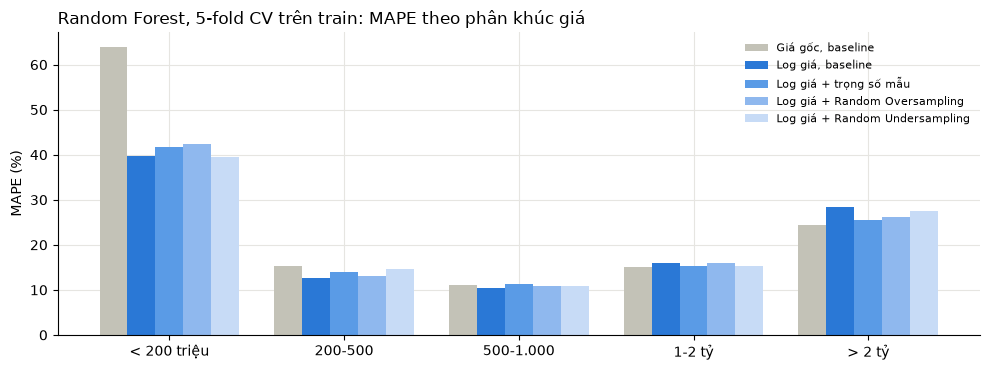

In [26]:
fig, ax = plt.subplots(figsize=(10, 3.8))
cv_colors = [GRAY, BLUE, "#5a9be6", "#8fb8ee", "#c7dbf6"]
w = 0.8 / len(cv_res)
for k, (name, col) in enumerate(zip(cv_res.index, cv_colors)):
    ax.bar(np.arange(len(SEG_LABELS)) + k * w, cv_res.loc[name, seg_cols].values.astype(float) * 100, w, color=col, label=name)
ax.set_xticks(np.arange(len(SEG_LABELS)) + (len(cv_res) - 1) / 2 * w); ax.set_xticklabels(SEG_LABELS)
ax.set_ylabel("MAPE (%)")
ax.set_title("Random Forest, 5-fold CV trên train: MAPE theo phân khúc giá", loc="left")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

### 7.1 Kết luận thí nghiệm
Đọc bảng trên (5-fold CV trên train, `random_state = 42`), tập trung vào MAPE:

**1. Log giá tốt hơn rõ rệt.** MAPE tổng giảm từ 0,211 (giá gốc) xuống 0,165 (log giá), và phân khúc `< 200 triệu` giảm mạnh nhất (0,64 → 0,40). Lý do: trên giá gốc, sai số bình phương bị xe đắt chi phối nên mô hình bỏ qua sai số tương đối ở xe rẻ. Đổi lại, giá gốc tốt hơn ở hai phân khúc đắt (`1-2 tỷ` 0,152 so với 0,159; `> 2 tỷ` 0,245 so với 0,285), cũng vì đúng lý do đó. MAE gần như không đổi (101 so với 99 triệu). Với thước đo chính là MAPE, **chọn log giá**.

**2. Các kỹ thuật cân bằng không cải thiện MAPE tổng của Random Forest, nhưng chuyển sai số giữa các phân khúc.**
- **Trọng số mẫu** giảm MAPE ở `> 2 tỷ` (0,285 → 0,254) và `1-2 tỷ` (0,159 → 0,152), nhưng làm xấu đi ở các phân khúc đông (`200-500`: 0,127 → 0,140). Vì vậy MAPE tổng tăng (0,165 → 0,175).
- **Oversampling** cho kết quả tương tự nhưng yếu hơn (`> 2 tỷ` 0,261, MAPE tổng 0,172). Nhân bản cùng vài trăm xe sang không tạo thêm thông tin mới.
- **Undersampling** bỏ khoảng 22% dữ liệu train mỗi fold, MAPE tổng tăng lên 0,174 và hầu như không giúp được `> 2 tỷ` (0,275).
- Nguyên nhân sâu xa: sai số ở xe sang đến chủ yếu từ **thiếu đặc trưng** (phiên bản, trang bị) chứ không phải từ việc ít mẫu.

**Quyết định:** mô hình cuối **huấn luyện trên log giá, không dùng kỹ thuật cân bằng**, vì thước đo chính là MAPE trên toàn bộ thị trường. Nếu ưu tiên định giá xe sang, trọng số mẫu là lựa chọn hợp lý: đổi khoảng 1 điểm % MAPE tổng lấy khoảng 3 điểm % ở phân khúc `> 2 tỷ`. Quyết định này chỉ dựa trên CV trên train; tập test không được dùng.

## 8. Xuất mô hình

Lưu các mô hình đã huấn luyện vào thư mục `model/` (nằm cạnh `src/`, tức `../model` khi chạy notebook trong `src`) để dùng lại mà không phải huấn luyện lại:

| File | Nội dung |
|---|---|
| `preprocessor.joblib` | bộ mã hóa one-hot + chuẩn hóa (đã fit trên train) |
| `ridge_sklearn.joblib`, `random_forest_sklearn.joblib` | mô hình thư viện |
| `ridge_scratch.npz` | vector trọng số của Ridge tự cài đặt (nghiệm đóng) |
| `random_forest_scratch.npz` | các cây và ngưỡng bin của rừng tự cài đặt, lưu dạng mảng NumPy (không dùng pickle nên không phụ thuộc định nghĩa lớp trong notebook) |
| `metadata.json` | danh sách đặc trưng, nhãn đã biết, tham số tốt nhất, metric trên test |
| `price_model.py` | hàm `load_model` / `predict_price` để dùng ngoài notebook |
| `*.pkl` | (tùy chọn) mỗi mô hình kèm bộ tiền xử lý trong một file, tạo bằng `python export_pkl.py` sau khi chạy notebook |

Dự đoán trả về **log giá**; `predict_price` đã `exp()` về triệu đồng.

In [27]:
import json, sys, joblib
from pathlib import Path
import sklearn

MODEL_DIR = Path("../model")       # thư mục model/ nằm cạnh src/
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(prep, MODEL_DIR / "preprocessor.joblib", compress=3)
joblib.dump(ridge_lib, MODEL_DIR / "ridge_sklearn.joblib", compress=3)
joblib.dump(rf_lib, MODEL_DIR / "random_forest_sklearn.joblib", compress=3)
np.savez_compressed(MODEL_DIR / "ridge_scratch.npz", w=ridge_closed.w_)

# Rừng tự cài đặt: lưu từng mảng của từng cây + ngưỡng bin
edges = rf_s.binner_.edges_
payload = {"n_trees": len(rf_s.trees_),
           "edges": np.concatenate(edges),
           "edge_offsets": np.cumsum([0] + [len(e) for e in edges])}
for i, t in enumerate(rf_s.trees_):
    payload.update({f"t{i}_feature": t.feature_, f"t{i}_thr": t.thr_, f"t{i}_left": t.left_,
                    f"t{i}_right": t.right_, f"t{i}_value": t.value_})
np.savez_compressed(MODEL_DIR / "random_forest_scratch.npz", **payload)

metadata = {
    "target": "ln(giá triệu đồng); dự đoán xong dùng exp() để ra triệu đồng",
    "cat_features": CAT, "num_features": NUM,
    "brands": sorted(set(df["carbrand_grp"]) - {"Hãng khác"}),
    "models": sorted(set(df["carmodel_grp"]) - {"Dòng khác"}),
    "categories": {c: sorted(df[c].unique().tolist()) for c in ["carorigin", "condition_ad", "gearbox", "fuel", "cartype"]},
    "best_params": {"ridge_alpha_sklearn_scale": float(best_alpha_lib),
                    "decision_tree_sklearn": gs_dt.best_params_,
                    "random_forest_sklearn": rs_rf.best_params_,
                    "random_forest_scratch": {**best_cfg, "n_estimators": N_TREES}},
    "test_metrics": {k: {m: round(float(v), 4) for m, v in r.items()} for k, r in results.items()},
    "sklearn_version": sklearn.__version__,
    "n_train": int(len(X_tr)), "random_state": RANDOM_STATE,
}
with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2, default=int)

sizes = pd.Series({p.name: p.stat().st_size / 1e6 for p in sorted(MODEL_DIR.iterdir()) if p.is_file() and p.suffix != ".pkl"})
sizes.round(2).to_frame("MB")

,MB
export_pkl.py,0.00
metadata.json,0.01
preprocessor.joblib,0.00
price_model.py,0.01
random_forest_scratch.npz,8.68
random_forest_sklearn.joblib,57.84
ridge_scratch.npz,0.00
ridge_sklearn.joblib,0.00


**Kiểm tra:** nạp lại mô hình từ `model/` bằng `price_model.py` (đi qua đường dự đoán độc lập với notebook) và so khớp với dự đoán đã tính ở trên trên toàn bộ tập test. Phải trùng khớp tuyệt đối.

In [28]:
sys.path.insert(0, str(MODEL_DIR))
import importlib, price_model
importlib.reload(price_model)

name_map = {"ridge_sklearn": "Ridge - thư viện", "ridge_scratch": "Ridge - tự cài đặt (nghiệm đóng)",
            "random_forest_sklearn": "Random Forest - thư viện", "random_forest_scratch": "Random Forest - tự cài đặt"}
raw_test = te[CAT + ["age", "mileage_km", "km_per_year", "carseats"]]
for key, label in name_map.items():
    p_loaded = price_model.predict_price(price_model.load_model(key), raw_test)
    print(f"{key:24s} max|Δ giá| so với trong notebook = {np.abs(p_loaded - preds[label]).max():.2e} triệu")
    assert np.allclose(p_loaded, preds[label], rtol=1e-9, atol=1e-6)

# Ví dụ dự đoán từ thông tin thô của một xe
demo = pd.DataFrame([{"carbrand": "Toyota", "carmodel": "Vios", "carorigin": "Việt Nam", "condition_ad": "Đã sử dụng",
                      "gearbox": "Tự động", "fuel": "Xăng", "cartype": "Sedan", "carseats": 5,
                      "mfdate": 2018, "mileage_km": 80000}])
pd.DataFrame({k: price_model.predict_price(price_model.load_model(k), demo) for k in name_map},
             index=["Toyota Vios 2018, 80.000 km (triệu)"]).round(0)

ridge_sklearn            max|Δ giá| so với trong notebook = 0.00e+00 triệu
ridge_scratch            max|Δ giá| so với trong notebook = 3.41e-12 triệu


random_forest_sklearn    max|Δ giá| so với trong notebook = 1.21e-11 triệu


random_forest_scratch    max|Δ giá| so với trong notebook = 0.00e+00 triệu


,ridge_sklearn,ridge_scratch,random_forest_sklearn,random_forest_scratch
"Toyota Vios 2018, 80.000 km (triệu)",288.0,288.0,299.0,300.0


## 9. Kết luận

Số liệu dưới đây lấy từ lần chạy với `random_state = 42` trên dữ liệu đã loại giá trả trước/đặt cọc (13.946 tin); chạy lại ở máy khác có thể lệch nhẹ. Các nhận xét dựa trên bảng ở mục 6.

**1. Mọi mô hình đều tốt hơn rõ rệt so với baseline.** Baseline luôn đoán trung vị có MAPE khoảng 0,85; Ridge giảm còn 0,22, Decision Tree 0,20 và Random Forest 0,16. Với Random Forest, khoảng 58% tin đăng được dự đoán lệch dưới 10% giá thật và 79% lệch dưới 20%; sai số điển hình (MedAPE) khoảng 8%.

**2. Random Forest tốt nhất, và chênh lệch có ý nghĩa thống kê.** Khoảng tin cậy bootstrap 95% của MAPE là 0,147-0,174 (Random Forest), so với 0,184-0,221 (Decision Tree) và 0,204-0,240 (Ridge). Khoảng của Random Forest không chồng lên khoảng của hai mô hình còn lại. R² trên log giá tăng từ khoảng 0,83 (Ridge, Decision Tree) lên 0,88.
- **Một cây → nhiều cây:** Decision Tree tốt nhất (không giới hạn độ sâu, `min_samples_leaf = 5`) có R² train 0,93 nhưng R² test 0,83, tức phương sai cao. Lấy trung bình 300 cây trên các mẫu bootstrap giảm MAPE từ 0,202 xuống 0,160 (giảm khoảng 21%) mà không cần thêm dữ liệu hay đặc trưng.
- **Cây so với tuyến tính:** Decision Tree và Ridge có R² (log) gần như bằng nhau (0,83), nhưng cây có MAPE và MedAPE thấp hơn (0,202 so với 0,220; 0,094 so với 0,121) và tốt hơn hẳn ở xe trên 2 tỷ (0,34 so với 0,47). Lý do: giá phụ thuộc phi tuyến và có tương tác (mức mất giá theo tuổi khác nhau giữa các hãng), điều Ridge chỉ xấp xỉ được bằng vài đặc trưng thêm (`age²`, log km).

**3. Cả ba mô hình đều kém hơn ở hai đầu của thang giá.**
- Xe dưới 200 triệu: MAPE 0,36 (Random Forest) đến 0,48 (Ridge). Sau khi loại 134 tin ghi giá trả trước/đặt cọc ở bước tiền xử lý, MAPE của Random Forest ở phân khúc này giảm từ 0,57 xuống 0,36, cho thấy phần lớn sai số trước đây đến từ **nhãn sai** chứ không phải từ mô hình. Phần còn lại là do giá thấp: một khoản chênh vài chục triệu (tình trạng, thương lượng) đã là phần trăm lớn, và xe đời cũ rất khác nhau về tình trạng thực tế mà dữ liệu không có. Có thể vẫn còn tin giá cọc mà quy tắc không bắt được (nhóm hãng-dòng-năm có dưới 3 xe).
- Xe trên 2 tỷ: MAPE 0,31 (Random Forest) và 0,47 (Ridge). Chỉ khoảng 3% dữ liệu và thiếu đặc trưng quyết định giá xe sang (phiên bản, trang bị). Các kỹ thuật cân bằng không giải quyết được (mục 7).
- Phân khúc giữa (200-1.000 triệu, chiếm khoảng 75% dữ liệu): MAPE khoảng 0,11-0,12 với Random Forest, đủ dùng để tham khảo giá.

**4. Log giá và xử lý mất cân bằng (mục 7, CV trên train).** Log giá giảm MAPE CV từ 0,211 xuống 0,165. Trọng số mẫu, oversampling và undersampling đều làm MAPE tổng tăng (0,172-0,175). Riêng trọng số mẫu giúp phân khúc `> 2 tỷ` (0,285 → 0,254). Mô hình cuối không dùng kỹ thuật cân bằng.

**5. Bản tự cài đặt cho kết quả gần tương đương bản thư viện, chứng tỏ cài đặt đúng.**
- Ridge: với cùng alpha, nghiệm đóng tự viết trùng sklearn đến sai số số học (hệ số lệch khoảng 1e-11); Gradient Descent có momentum cho dự đoán gần như trùng. CV tự viết chọn alpha 0,56 còn `GridSearchCV` chọn 0,32, do hai cách chia fold khác nhau trong khi đường CV rất phẳng ở đoạn này (CV RMSE như nhau đến 4 chữ số). Metric trên test gần như trùng (MAPE 0,220 cả hai).
- Decision Tree: với cùng tham số, cây tự viết đạt R² (log) test 0,823 so với 0,828 của sklearn, MAPE 0,200 so với 0,202.
- Random Forest: MAPE 0,165 (tự viết) so với 0,160 (thư viện), hai khoảng tin cậy bootstrap chồng lên nhau. Chênh lệch nhỏ đến từ việc rời rạc hóa 32 bin, cấu hình tìm bằng OOB trên ít cấu hình hơn, và cách chọn ngẫu nhiên khác nhau. Hai bản cho **cùng thứ hạng đặc trưng quan trọng** (mục 6.2).

**6. Chi phí tính toán là điểm khác biệt lớn nhất giữa hai bản cài đặt.** Rừng tự viết bằng Python thuần mất khoảng 3,5 phút để huấn luyện, so với khoảng 5 giây của thư viện, vì thư viện dùng mã C/Cython và chạy song song nhiều lõi. Đây là lý do thực tế để dùng thư viện khi triển khai, còn tự cài đặt có giá trị để hiểu thuật toán.

**7. Tinh chỉnh tham số có tác dụng.** Random Forest cần cây sâu (`max_depth` 30) và lá nhỏ (`min_samples_leaf` 1-2): các cấu hình nông (độ sâu 10) có OOB RMSE khoảng 0,36, tệ hơn nhiều so với khoảng 0,28 của cấu hình sâu. Dữ liệu có nhiều tổ hợp hãng-dòng-đời xe riêng biệt nên mô hình cần đủ độ phức tạp để học từng nhóm.

**Hạn chế và hướng phát triển**
- Dữ liệu giá là **giá rao bán**, không phải giá giao dịch thực; luôn có phần thương lượng mà mô hình không biết.
- Giá dự đoán là `exp()` của dự đoán log giá, tức ước lượng **trung vị** của giá, hơi thấp hơn giá trung bình. Điều này phù hợp với MAPE nên không hiệu chỉnh.
- **Tin đăng lại:** khoảng 15% dòng test có một dòng train giống hệt mọi đặc trưng kể cả số km, nhiều khả năng là cùng một xe đăng lại (mục 6.4). Trên nhóm không có bản sao, MAPE của Random Forest là 0,171 (so với 0,160 trên toàn bộ test), nên con số 0,160 hơi lạc quan. Cách chặt hơn là chia train/test theo nhóm (`StratifiedGroupKFold`) để mọi bản sao của một xe nằm cùng một phía.
- Bộ lọc giá trả trước/đặt cọc dùng giá (biến mục tiêu) trên toàn bộ dữ liệu. Đây là bước sửa lỗi nhãn, không đưa thông tin giá vào đặc trưng, nhưng cần nêu rõ trong báo cáo.
- Thiếu đặc trưng quan trọng: phiên bản/trang bị, tình trạng thân vỏ và nội thất, khu vực đăng tin (có trong URL nhưng chưa đưa vào), số đời chủ.
- Tập test không dùng để chọn mô hình, tham số, cách biến đổi biến mục tiêu hay kỹ thuật cân bằng (tất cả đều chọn bằng CV/OOB trên train), nên số liệu test là ước lượng khách quan về hiệu năng với dữ liệu mới cùng phân phối (trừ ảnh hưởng của tin đăng lại nói trên).
- Hướng cải thiện: thêm khu vực từ URL; crawl mô tả tin để lọc giá cọc theo từ khóa; thử Gradient Boosting (HistGradientBoosting/XGBoost); dùng hàm mất mát theo phần trăm để cải thiện hai đầu thang giá.